# Análisis exploratorio: agricultura, clima y edafología

Esta notebook carga el conjunto integrado de agricultura, clima y edafología para 2003–2025. También conserva las capas originales de INEGI para explorar espacialmente las unidades y perfiles de suelo.

In [1]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

from proyecto_agronomia.config import PROCESSED_DATA_DIR, RAW_DATA_DIR

RUTA_AGRICULTURA_CLIMA = (
    PROCESSED_DATA_DIR / "agricultura_clima_edafologia_2003_2025.csv"
)
DIRECTORIO_EDAFOLOGIA = RAW_DATA_DIR / "edafologia" / "serie_iii" / "conjunto_de_datos"
RUTA_EDAFOLOGIA_AREA = DIRECTORIO_EDAFOLOGIA / "conj_nac_inf_edaf_esc_250k_ser_III_area.shp"
RUTA_EDAFOLOGIA_PUNTOS = DIRECTORIO_EDAFOLOGIA / "conj_nac_inf_edaf_esc_250k_ser_III_pto.shp"

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

for ruta in [RUTA_AGRICULTURA_CLIMA, RUTA_EDAFOLOGIA_AREA, RUTA_EDAFOLOGIA_PUNTOS]:
    if not ruta.exists():
        raise FileNotFoundError(f"No se encontró el archivo requerido: {ruta}")

print("Archivos localizados correctamente.")

2026-10-29 20:36:15.521 | INFO     | proyecto_agronomia.config:<module>:14 - PROJ_ROOT path is: B:\MCD2\JW\agro\proyecto_agronomia


Archivos localizados correctamente.


## 1. Agricultura, clima y suelo

Cada registro corresponde a una observación agrícola. El clima de NASA POWER está alineado con su ciclo productivo y los atributos edafológicos dominantes están asociados mediante `cvegeo`.

In [2]:
df_agricultura_clima = pd.read_csv(
    RUTA_AGRICULTURA_CLIMA,
    dtype={"cvegeo": "string"},
    low_memory=False,
)
df_agricultura_clima["cvegeo"] = df_agricultura_clima["cvegeo"].str.zfill(5)

print(f"Dimensiones: {df_agricultura_clima.shape}")
print(f"Memoria aproximada: {df_agricultura_clima.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")
display(df_agricultura_clima.head())

Dimensiones: (825089, 70)
Memoria aproximada: 1,074.9 MB


,Anio,Idestado,Nomestado,Idddr,Nomddr,Idcader,Nomcader,Idmunicipio,Nommunicipio,Idciclo,Nomcicloproductivo,Idmodalidad,Nommodalidad,Idunidadmedida,Nomunidad,Idcultivo,Nomcultivo,Sembrada,Cosechada,Siniestrada,Volumenproduccion,Rendimiento,Precio,Valorproduccion,Nomcultivo Sin Um,Preciomediorural,cvegeo,precipitacion_ciclo_mm,dias_clima_ciclo,temperatura_media_ciclo_c,temperatura_ene_c,temperatura_feb_c,temperatura_mar_c,temperatura_abr_c,temperatura_may_c,temperatura_jun_c,temperatura_jul_c,temperatura_ago_c,temperatura_sep_c,temperatura_oct_c,temperatura_nov_c,temperatura_dic_c,precipitacion_ene_mm,precipitacion_feb_mm,precipitacion_mar_mm,precipitacion_abr_mm,precipitacion_may_mm,precipitacion_jun_mm,precipitacion_jul_mm,precipitacion_ago_mm,precipitacion_sep_mm,precipitacion_oct_mm,precipitacion_nov_mm,precipitacion_dic_mm,temperatura_oct_anterior_c,temperatura_nov_anterior_c,temperatura_dic_anterior_c,precipitacion_oct_anterior_mm,precipitacion_nov_anterior_mm,precipitacion_dic_anterior_mm,grupo_suelo_dominante,grupo_suelo_dominante_pct,textura_dominante,textura_dominante_pct,fase_fisica_dominante,fase_fisica_dominante_pct,fase_quimica_dominante,fase_quimica_dominante_pct,grupos_suelo_n,nombre_suelo_wrb
0,2003,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Otoño-Invierno,1,Riego,200201,Tonelada,5490000,Avena forrajera en verde,1062.0,1062.0,0.0,28529.0,26.86,323.4,9226278.6,NaN,NaN,01001,84.8,182,13.835165,11.774194,13.915,14.978387,19.277,22.555161,20.925667,18.777742,18.896129,18.098667,16.434839,14.971667,11.090323,4.16,1.98,0.0,0.99,12.23,108.17,204.01,111.18,147.91,48.57,3.47,0.0,17.647097,13.39,11.299677,51.92,26.61,0.13,PH,24.72,2.0,88.81,lep,35.3,NaN,NaN,11,Phaeozem
1,2003,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Otoño-Invierno,1,Riego,200201,Tonelada,5900000,Cebada forrajera en verde,2.0,2.0,0.0,54.0,27.0,250.0,13500.0,NaN,NaN,01001,84.8,182,13.835165,11.774194,13.915,14.978387,19.277,22.555161,20.925667,18.777742,18.896129,18.098667,16.434839,14.971667,11.090323,4.16,1.98,0.0,0.99,12.23,108.17,204.01,111.18,147.91,48.57,3.47,0.0,17.647097,13.39,11.299677,51.92,26.61,0.13,PH,24.72,2.0,88.81,lep,35.3,NaN,NaN,11,Phaeozem
2,2003,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Otoño-Invierno,1,Riego,200201,Tonelada,5980000,Centeno forrajero en verde,17.0,17.0,0.0,1020.0,60.0,350.0,357000.0,NaN,NaN,01001,84.8,182,13.835165,11.774194,13.915,14.978387,19.277,22.555161,20.925667,18.777742,18.896129,18.098667,16.434839,14.971667,11.090323,4.16,1.98,0.0,0.99,12.23,108.17,204.01,111.18,147.91,48.57,3.47,0.0,17.647097,13.39,11.299677,51.92,26.61,0.13,PH,24.72,2.0,88.81,lep,35.3,NaN,NaN,11,Phaeozem
3,2003,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Otoño-Invierno,1,Riego,200201,Tonelada,9090000,Triticale forrajero en verde,24.0,24.0,0.0,720.0,30.0,400.0,288000.0,NaN,NaN,01001,84.8,182,13.835165,11.774194,13.915,14.978387,19.277,22.555161,20.925667,18.777742,18.896129,18.098667,16.434839,14.971667,11.090323,4.16,1.98,0.0,0.99,12.23,108.17,204.01,111.18,147.91,48.57,3.47,0.0,17.647097,13.39,11.299677,51.92,26.61,0.13,PH,24.72,2.0,88.81,lep,35.3,NaN,NaN,11,Phaeozem
4,2003,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Otoño-Invierno,1,Riego,200201,Tonelada,15050000,Pastos y praderas,415.0,415.0,0.0,25830.0,62.24,314.9,8133867.0,NaN,NaN,01001,84.8,182,13.835165,11.774194,13.915,14.978387,19.277,22.555161,20.925667,18.777742,18.896129,18.098667,16.434839,14.971667,11.090323,4.16,1.98,0.0,0.99,12.23,108.17,204.01,111.18,147.91,48.57,3.47,0.0,17.647097,13.39,11.299677,51.92,26.61,0.13,PH,24.72,2.0,88.81,lep,35.3,NaN,NaN,11,Phaeozem


In [3]:
columnas_requeridas = {
    "cvegeo",
    "Anio",
    "Nomcicloproductivo",
    "precipitacion_ciclo_mm",
    "temperatura_media_ciclo_c",
    "grupo_suelo_dominante",
    "nombre_suelo_wrb",
    "grupo_suelo_dominante_pct",
    "grupos_suelo_n",
    "textura_dominante",
}
faltantes = columnas_requeridas - set(df_agricultura_clima.columns)
assert not faltantes, f"Faltan columnas requeridas: {sorted(faltantes)}"
assert df_agricultura_clima["Anio"].between(2003, 2025).all()

resumen_agricultura_clima = (
    df_agricultura_clima.groupby(["Anio", "Nomcicloproductivo"])
    .agg(
        registros=("cvegeo", "size"),
        municipios=("cvegeo", "nunique"),
        precipitacion_disponible=("precipitacion_ciclo_mm", "count"),
        temperatura_disponible=("temperatura_media_ciclo_c", "count"),
        suelo_disponible=("grupo_suelo_dominante", "count"),
    )
)
display(resumen_agricultura_clima)

registros  municipios  precipitacion_disponible  \
Anio Nomcicloproductivo                                                    
2003 Otoño-Invierno           9858        1897                      9858   
     Perennes                10488        2118                     10488   
     Primavera-Verano        15321        2362                     15321   
2004 Otoño-Invierno           9935        1902                      9935   
     Perennes                10838        2130                     10838   
...                            ...         ...                       ...   
2024 Perennes                11631        2290                     11631   
     Primavera-Verano        16077        2406                     16077   
2025 Otoño-Invierno           9099        1923                      9099   
     Perennes                11763        2292                     11763   
     Primavera-Verano        15040        2393                     15040   

                         temperatura_disponible  suelo_disponible  
Anio Nomcicloproductivo                                            
2003 Otoño-Invierno                        9858              9858  
     Perennes                             10488             10488  
     Primavera-Verano                     15321             15321  
2004 Otoño-Invierno                        9935              9935  
     Perennes                             10838             10838  
...                                         ...               ...  
2024 Perennes                             11631             11631  
     Primavera-Verano                     16077             16077  
2025 Otoño-Invierno                        9099              9099  
     Perennes                             11763             11763  
     Primavera-Verano                     15040             15040  

[69 rows x 5 columns]

## 2. Unidades edafológicas

La capa de áreas contiene las unidades cartográficas de suelo. Esta será la fuente principal para una futura caracterización municipal ponderada por superficie.

In [4]:
gdf_edafologia_area = gpd.read_file(RUTA_EDAFOLOGIA_AREA)

print(f"Dimensiones: {gdf_edafologia_area.shape}")
print(f"CRS: {gdf_edafologia_area.crs}")
print(f"Geometrías vacías: {gdf_edafologia_area.geometry.is_empty.sum():,}")
print(f"Geometrías nulas: {gdf_edafologia_area.geometry.isna().sum():,}")
display(gdf_edafologia_area.head())

Dimensiones: (73356, 17)
CRS: PROJCS["ITRF_1992_Lambert_Conformal_Conic",GEOGCS["ITRF92",DATUM["International_Terrestrial_Reference_Frame_1992",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6651"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",12],PARAMETER["central_meridian",-102],PARAMETER["standard_parallel_1",17.5],PARAMETER["standard_parallel_2",29.5],PARAMETER["false_easting",2500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Geometrías vacías: 0
Geometrías nulas: 0


,OBJECTID,Clave_wrb,Grupo1,Califp_g1,Califs_g1,Grupo2,Califp_g2,Califs_g2,Grupo3,Califp_g3,Clase_tex,Lmte_sup,Fase_fis_u,Fase_qui_u,Shape_Leng,Shape_Area,geometry
0,51100,TCek-ub,TC,ek,ub,N,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,4869.986820,1.279462e+06,"POLYGON ((1967990.852 1371330.6, 1967390.267 1372088.424, 1967381.101 1372083.163, 1967372.655 1372078.341, 1967264...."
1,51101,TCek-ub,TC,ek,ub,N,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,13456.884838,4.277815e+06,"POLYGON ((1957288.265 1375973.972, 1957735.508 1375656.365, 1958014.225 1376012.863, 1958529.43 1375613.802, 1958753..."
2,51102,TCek-ub,TC,ek,ub,N,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,7494.539810,2.320522e+06,"POLYGON ((1974481.215 1386905.387, 1974522.564 1386839.623, 1974571.786 1386761.284, 1974722.821 1386556.573, 197436..."
3,51103,TCek-ub,TC,ek,ub,N,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,4987.291306,1.022117e+06,"POLYGON ((1958012.275 1389396.422, 1958157.935 1388933.952, 1958167.391 1388903.913, 1958335.274 1388992.001, 195850..."
4,51104,TCek-ub,TC,ek,ub,N,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A,17304.215845,6.533944e+06,"POLYGON ((1958644.275 1406804.429, 1958631.865 1406561.196, 1958267.943 1406596.021, 1958135.573 1405889.109, 195812..."


In [5]:
columnas_edafologicas = [
    "Grupo1", "Grupo2", "Grupo3", "Clase_tex",
    "Lmte_sup", "Fase_fis_u", "Fase_qui_u",
]

resumen_edafologia = pd.DataFrame(
    {
        "tipo": gdf_edafologia_area[columnas_edafologicas].dtypes.astype(str),
        "valores_unicos": gdf_edafologia_area[columnas_edafologicas].nunique(dropna=False),
        "nulos": gdf_edafologia_area[columnas_edafologicas].isna().sum(),
    }
)
display(resumen_edafologia)

for columna in columnas_edafologicas:
    print(f"\n{columna}")
    display(gdf_edafologia_area[columna].value_counts(dropna=False).head(15).to_frame("unidades"))

,tipo,valores_unicos,nulos
Grupo1,str,29,0
Grupo2,str,29,0
Grupo3,str,29,0
Clase_tex,str,4,0
Lmte_sup,str,5,0
Fase_fis_u,str,11,0
Fase_qui_u,str,7,0



Grupo1


,unidades
Grupo1,
LP,15211
RG,10590
PH,8856
CL,7883
VR,4749
LV,4392
CM,3705
SA,3579
TC,2878



Grupo2


,unidades
Grupo2,
N,25782
RG,9351
LP,8921
PH,5912
CM,4163
N/A,3579
LV,3345
VR,3001
CL,2954


...

,unidades
Lmte_sup,
N,35685
P,18698
G,12521
N/A,6450
p,2



Fase_fis_u


,unidades
Fase_fis_u,
N,25773
lep,22738
N/A,6450
len,6398
li,5669
pcp,3952
pcn,1352
pdp,372
pdn,274



Fase_qui_u


,unidades
Fase_qui_u,
N,60427
N/A,6457
so,3485
sz,1211
qs,1169
qz,539
jz,68


### Mapa nacional de grupos de suelo

La capa de polígonos representa las unidades edafológicas de INEGI Serie III. El color corresponde al grupo principal de suelo (`Grupo1`) de la clasificación WRB.

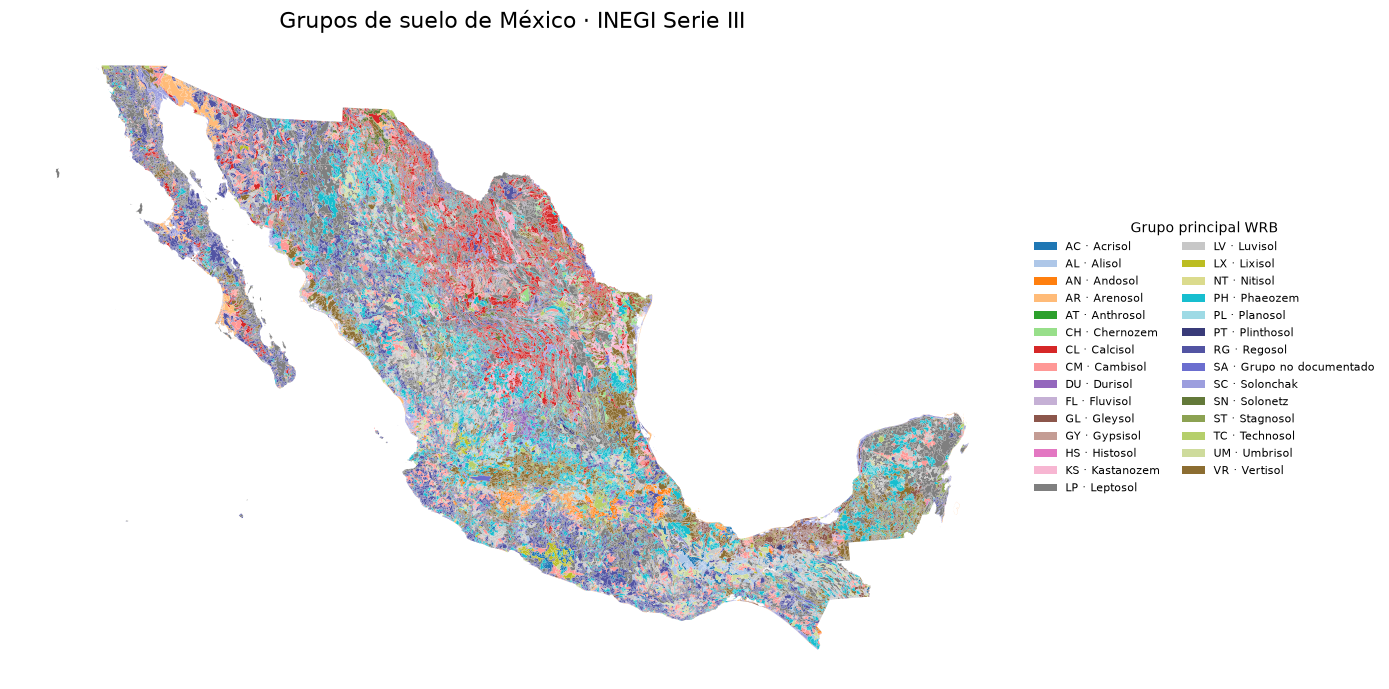

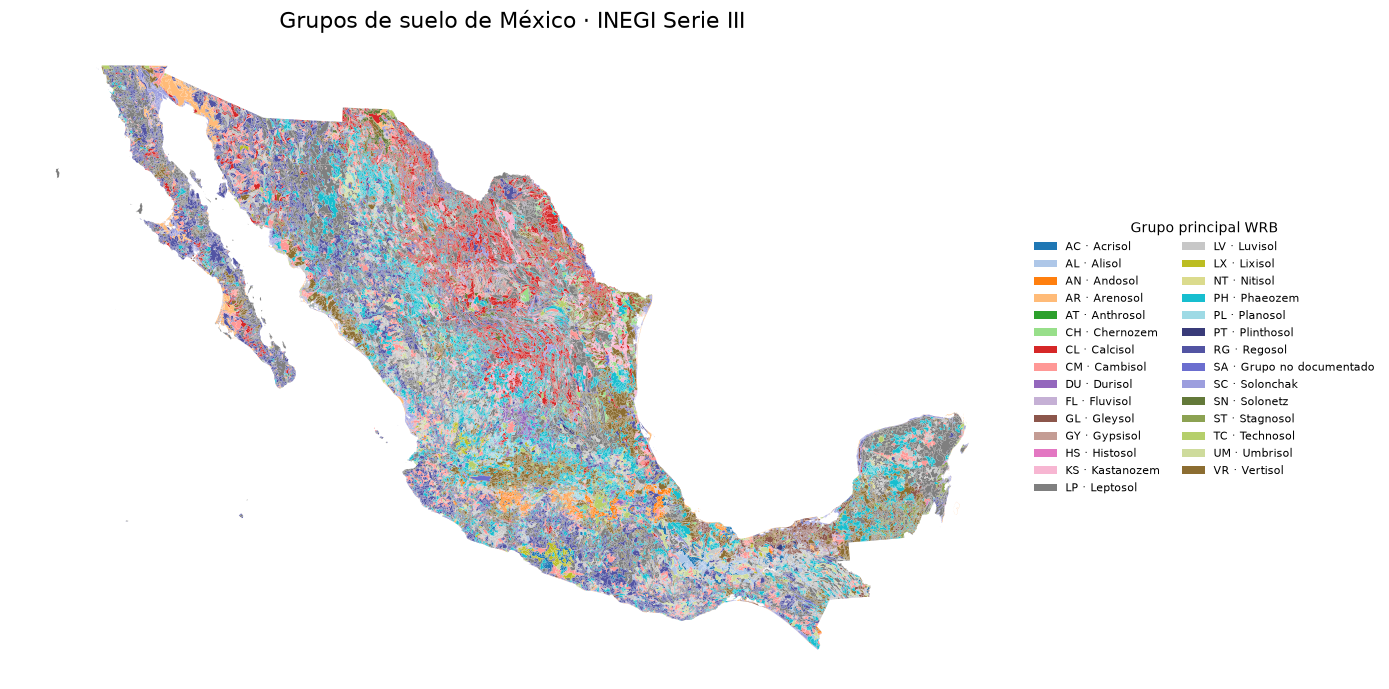

In [6]:
from proyecto_agronomia.plots import crear_mapa_edafologia

fig, ax, gdf_mapa_edafologia = crear_mapa_edafologia(
    gdf_edafologia_area,
    columna="Grupo1",
)
display(fig)

## 3. Perfiles y horizontes de suelo

La capa puntual contiene observaciones de perfiles y horizontes. Se conserva separada porque sus mediciones no representan automáticamente a todo el municipio.

In [7]:
gdf_edafologia_puntos = gpd.read_file(RUTA_EDAFOLOGIA_PUNTOS)

print(f"Dimensiones: {gdf_edafologia_puntos.shape}")
print(f"CRS: {gdf_edafologia_puntos.crs}")
print(f"Sitios: {gdf_edafologia_puntos['Id_Sitio'].nunique():,}")
print(f"Horizontes: {gdf_edafologia_puntos['Id_Hte'].nunique():,}")
display(gdf_edafologia_puntos.head())

Dimensiones: (20714, 115)
CRS: PROJCS["ITRF_1992_Lambert_Conformal_Conic",GEOGCS["ITRF92",DATUM["International_Terrestrial_Reference_Frame_1992",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6651"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",12],PARAMETER["central_meridian",-102],PARAMETER["standard_parallel_1",17.5],PARAMETER["standard_parallel_2",29.5],PARAMETER["false_easting",2500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Sitios: 5,318
Horizontes: 20,714


,OBJECTID,Id_Sitio,Id_Hte,Numero_Hte,Limite_sup,Limite_inf,Contra_hte,Forma_hor,HCl,H2O2,Humed_apar,Forma_estr,Tam_gr_la,Tam_pr_co,Tam_bl_mi,Desar_estr,Peliculas,Pel_natur,Facetas,Grietas,Col_hum_c,Col_seco_c,Cons_seco,Cons_hum,Adhesivid,Plasticid,Text_campo,Gravas,Piedras,Concrecion,Conc_color,Nodulos,Nodu_color,Manchas,Manch_colo,Raices,Cementac,Nomen_hte,Horiz_diag,Prop_diag1,Mater_diag,Horiz_di_1,Prop_diag2,Mater_di_1,Horiz_di_2,Prop_diag3,Mater_di_2,R,L,A,Desc_r_l_a,Clase_text,Esq_grava,Esq_piedra,Col_seco_l,Col_hum_l,CE,pH,CO,CIC,SB,SNa,K,Ca,Na,Mg,P2O5,CaCO3,CaSO4,DA,Na_Mg,Id_foto,Cal_pos,FID_,OBJECTID_1,Id_Sitio_1,Coord_x,Coord_y,Fecha,Clave_wrb,Gpo_suelo,Calif_prim,Calif_sec,Fase_fisic,Fase_quim,Altitud,Precip,Temp,Clima,Prov_fisio,Subpro_fis,Topoforma,Roca_subya,Edad_geol,Edad_geofo,Relieve,Modo_forma,Cober_tier,Pos_pend,Forma_pend,Grad_pend,Compl_pend,Orien_pend,Long_pend,Pedreg_sup,Afloramien,Escurr_sup,Infiltra,Superf_sue,Tipo_eros,Forma_eros,Grado_eros,Influe_hum,Fact_nociv,geometry
0,462,F1202-306,F1202-306-1,1,0,45,Abrupto,Plana,Muy débil,No disponible,Húmedo,Bloques Subangulares,No aplicable,No aplicable,Fino,Débil,Ninguno,No aplicable,Ninguno,N,10YR3/4,N/D,Blanda,Muy friable,Ligera,Ligera,Areno - francosa,Ninguno,Ninguno,N,N/A,N,N/A,N,N/A,21,N,An,Ninguno,Ninguno,Mineral,Ninguno,Ninguno,Ninguno,Ninguno,Ninguno,Ninguno,12,12,76,No disponible,Franco - arenosa,0,0,10YR5/4,10YR3/4,0.0,8.8,0.2,7.1,72.0,6.0,0.3,3.1,0.4,1.2,0.0,0.0,0.0,1.56,0.0,N/D,Definida,196,293,F1202-306,1666621.810,1320082.507,2013-09-09,"RGeu(lo,oh,qs)/2",Regosol,Éutrico,Loámico,Ninguno,Protosódica,223,300,22,BWh,Península de Baja California,Llanos de la Magdalena,Llanura,Conglomerado,Cuaternario,Senil,Casi plano,Aluvial,Matorral xerófilo,Parte baja y depresión,Convexo,1,Lisa,Sur,30,Ninguno,Ninguno,Medio,Drenado,Ninguno,Hídrica,Laminar,Leve,Escasa,Otro,POINT (1666621.81 1320082.507)
1,463,F1206-301,F1206-301-1,1,0,30,Abrupto,Irregular,Muy débil,No disponible,Seco,Bloques Subangulares,No aplicable,No aplicable,Fino,Débil,Ninguno,No disponible,Ninguno,N,N/A,N/A,No disponible,Suelta,Ninguno,Ninguno,Areno - francosa,Ninguno,Ninguno,N,N/A,N,N/A,N,N/A,11,N,An1,Ninguno,Ninguno,Mineral,Ninguno,Ninguno,Ninguno,Ninguno,Ninguno,Ninguno,10,11,79,No disponible,Franco - arenosa,0,0,10YR4/4,10YR3/3,0.0,7.0,0.3,7.0,73.0,8.6,0.3,3.7,0.6,0.6,0.0,0.0,0.0,1.53,0.0,N/D,Definida,197,294,F1206-301,1696735.628,1239805.750,2013-09-10,"RGpr-eu(lo,oh)/2",Regosol,Prótico,Éutrico,Ninguno,Ninguno,221,300,22,BS0h,Península de Baja California,Del Cabo,Lomerío,Granodiorita-Tonalita,Cretácico,Joven,Levemente ondulado,Coluvio-aluvial,Selva caducifolia,Pendiente media o espalda de ladera,Cóncavo,5,Lisa,Norte,30,Ninguno,Ninguno,Medio,Drenado,Ninguno,Hídrica,Laminar,Moderado,Moderada,Sobrepastoreo,POINT (1696735.628 1239805.75)
2,464,F1203-310,F1203-310-1,1,0,14,Abrupto,Irregular,Muy débil,No disponible,Seco,Bloques Subangulares,No aplicable,No aplicable,Fino,Moderado,Ninguno,No disponible,Ninguno,N,10YR5.5/3,10YR7/3,Muy dura,Firme,Ligera,Moderada,Franca,Ninguno,Ninguno,N,N/A,N,N/A,N,N/A,21,N,A,Ninguno,Ninguno,Mineral,Ninguno,Ninguno,Ninguno,Ninguno,Ninguno,Ninguno,23,10,67,No disponible,Franco - arcillo - arenosa,0,0,10YR6/4,2.5YR5/4,0.0,7.0,0.1,11.9,68.0,4.9,0.5,4.5,0.6,2.5,0.0,0.0,0.0,1.59,0.0,N/D,Definida,198,295,F1203-310,1726139.818,1302310.206,2013-09-11,"LPcm(lo,oh,qs)/2",Leptosol,Cámbico,Loámico,Epiléptico,Protosódica,36,300,22,BWh,Península de Baja California,Del Cabo,Lomerío,Conglomerado,Cuaternario,Madura,Casi plano,Residual,Matorral xerófilo,Pendiente media o espalda de ladera,Cóncavo,10,Lisa,Sur,30,Ninguno,Ninguno,Medio,Drenado,Otros,Hídrica,Laminar,Moderado,Moderada,Ninguno,POINT (1726139.818 1302310.206)
3,465,F1203-309,F1203-309-1,1,0,10,Abrupto,Plana,Muy débil,No disponible,Ligeramente húmedo,Bloques Subangulares,No aplicable,No aplicable,Fino,Débil,Ninguno,No disponible,Ninguno,N,7.5YR3.5/4,7.5YR6/4,Suelta,Suelta,Ligera,Ligera,Franco - arenosa,Ninguno,Ninguno,N,N/

In [8]:
variables_laboratorio = [
    "R", "L", "A", "CE", "pH", "CO", "CIC", "SB",
    "SNa", "K", "Ca", "Na", "Mg", "P2O5",
    "CaCO3", "CaSO4", "DA", "Na_Mg",
]
variables_laboratorio = [
    columna for columna in variables_laboratorio
    if columna in gdf_edafologia_puntos.columns
]

disponibilidad_laboratorio = pd.DataFrame(
    {
        "registros_disponibles": gdf_edafologia_puntos[variables_laboratorio].notna().sum(),
        "cobertura_pct": (
            gdf_edafologia_puntos[variables_laboratorio].notna().mean() * 100
        ).round(2),
        "valores_unicos": gdf_edafologia_puntos[variables_laboratorio].nunique(),
    }
)
display(disponibilidad_laboratorio)

,registros_disponibles,cobertura_pct,valores_unicos
R,20714,100.0,87
L,20714,100.0,81
A,20714,100.0,100
CE,20714,100.0,823
pH,20714,100.0,608
CO,20714,100.0,561
CIC,20714,100.0,920
SB,20714,100.0,1139
SNa,20714,100.0,1429
K,20714,100.0,591


## 4. Mapa municipal de cultivos

Para representar varios cultivos en un mismo municipio se selecciona el de mayor superficie cosechada. Los cultivos fuera de los principales se agrupan como `Otros`. Esta regla evita comparar volúmenes expresados en productos o unidades diferentes.

In [9]:
from proyecto_agronomia.config import FIGURES_DIR, INEGI_INTERIM_DIR
from proyecto_agronomia.plots import (
    crear_animacion_agricultura_clima,
    crear_mapa_cultivos,
    preparar_geometrias_municipales,
)

RUTA_MUNICIPIOS = INEGI_INTERIM_DIR / "municipios_mexico_inegi.geojson"
if not RUTA_MUNICIPIOS.exists():
    raise FileNotFoundError(f"No se encontró la capa municipal: {RUTA_MUNICIPIOS}")

gdf_municipios = gpd.read_file(RUTA_MUNICIPIOS)
gdf_municipios_mapa = preparar_geometrias_municipales(
    gdf_municipios,
    tolerancia_m=1_000,
)

print(f"Municipios disponibles: {gdf_municipios_mapa['cvegeo'].nunique():,}")
print(f"CRS para mapas: {gdf_municipios_mapa.crs}")
display(df_agricultura_clima['Nomcicloproductivo'].value_counts().to_frame('registros'))

Municipios disponibles: 2,478
CRS para mapas: EPSG:6372


,registros
Nomcicloproductivo,
Primavera-Verano,354841
Perennes,253778
Otoño-Invierno,216470


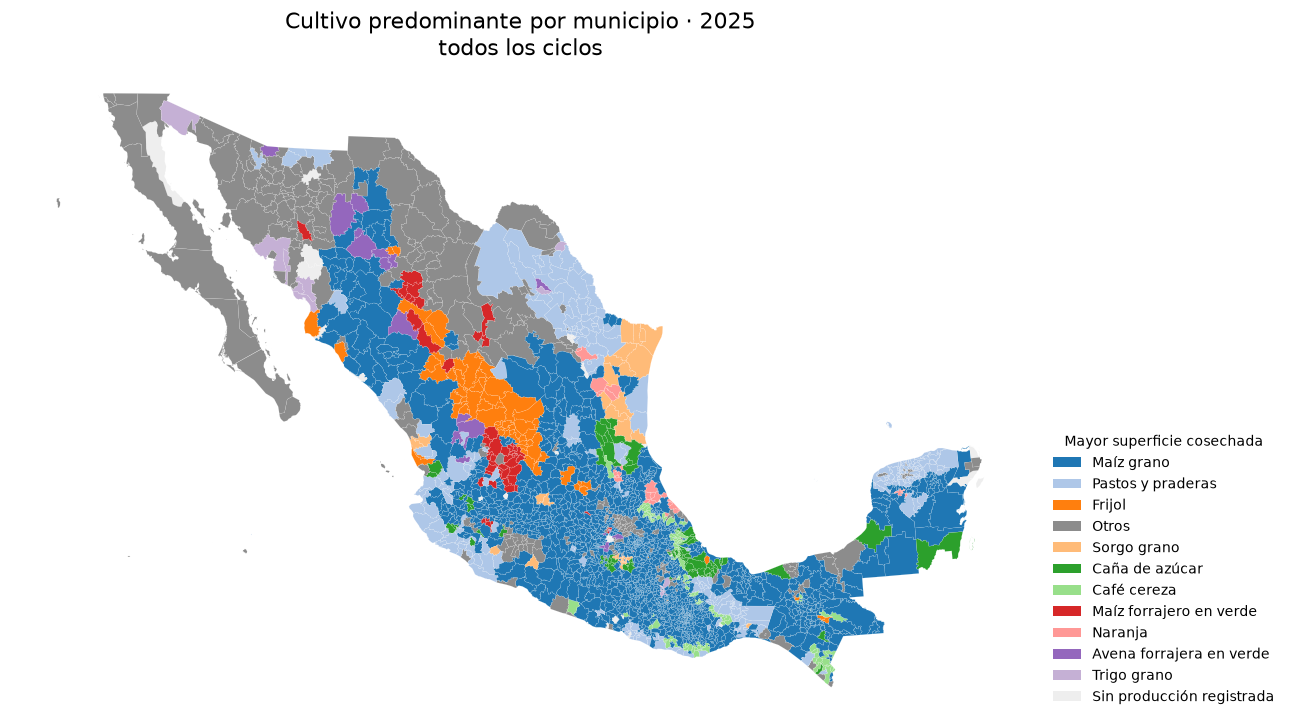

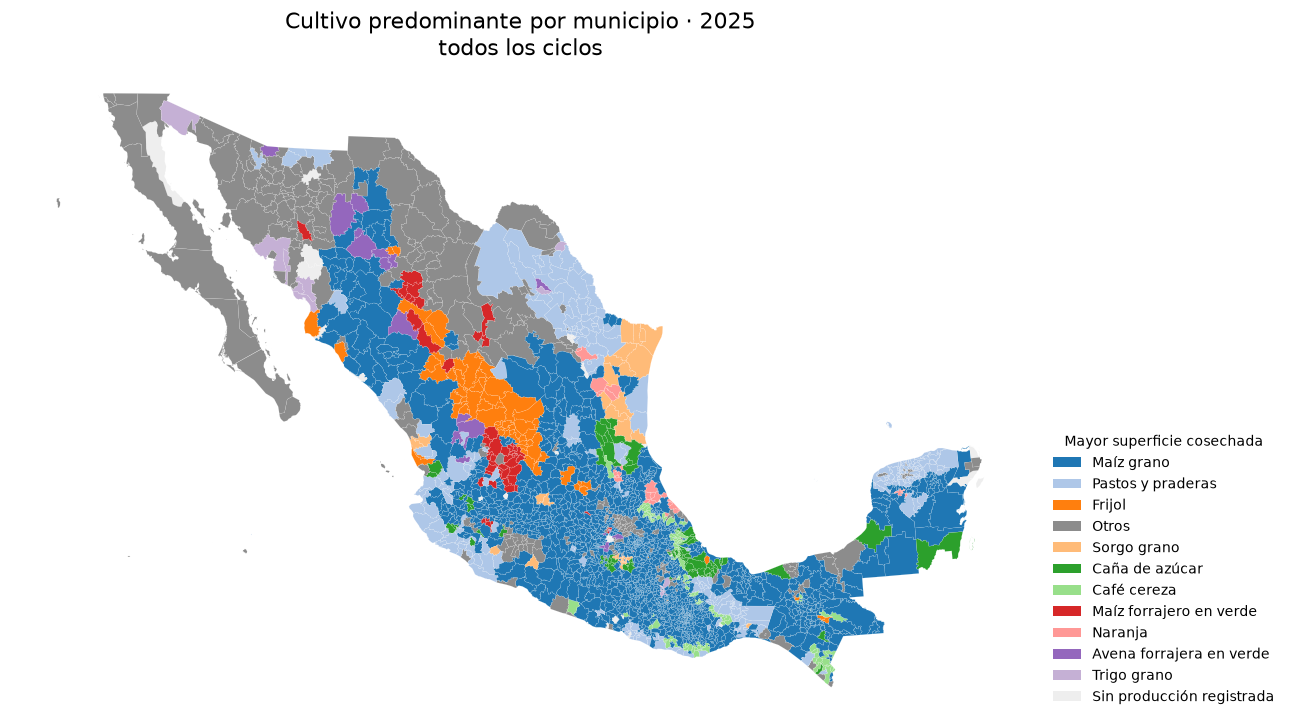

In [10]:
ANIO_MAPA = 2025
CICLO_MAPA = None  # Ejemplo: "Otoño-Invierno" o "Primavera-Verano"

fig, ax, gdf_mapa_cultivos = crear_mapa_cultivos(
    df_agricultura_clima,
    gdf_municipios_mapa,
    anio=ANIO_MAPA,
    ciclo=CICLO_MAPA,
    top_n=10,
)
display(fig)

## 5. Animación anual de agricultura y clima

La animación compara el cultivo predominante con la temperatura media y la precipitación anual. Las escalas climáticas permanecen fijas entre fotogramas para que los cambios sean comparables. El clima disponible es anual; el filtro por ciclo afecta únicamente a la producción agrícola.

In [11]:
GENERAR_VIDEO = False
CICLO_VIDEO = None  # Cambiar por un ciclo para crear una animación específica
RUTA_VIDEO = FIGURES_DIR / "agricultura_clima_2003_2025.gif"

if GENERAR_VIDEO:
    ruta_generada = crear_animacion_agricultura_clima(
        df_agricultura_clima,
        gdf_municipios_mapa,
        ruta_salida=RUTA_VIDEO,
        ciclo=CICLO_VIDEO,
        top_n=10,
        fps=2,
    )
    print(f"Animación guardada en: {ruta_generada}")
else:
    print("Vista previa lista. Cambia GENERAR_VIDEO a True para crear el GIF.")

Vista previa lista. Cambia GENERAR_VIDEO a True para crear el GIF.


## 6. Clima municipal mensual

El clima mensual se explora como un conjunto independiente. Las escalas visuales se calculan para todo 2003–2025 y permanecen fijas para que los meses del GIF sean comparables.

In [12]:
from proyecto_agronomia.config import NASA_POWER_PROCESSED_DIR
from proyecto_agronomia.plots import (
    crear_animacion_clima_mensual,
    crear_mapa_clima_mensual,
)

RUTA_CLIMA_MENSUAL = (
    NASA_POWER_PROCESSED_DIR / "clima_municipal_mensual_2002_2025.csv"
)
if not RUTA_CLIMA_MENSUAL.exists():
    raise FileNotFoundError(f"No se encontró: {RUTA_CLIMA_MENSUAL}")

columnas_clima_mensual = [
    "cvegeo", "anio", "mes",
    "temperatura_media_mes_c", "precipitacion_mes_mm",
    "dias_esperados", "dias_temperatura", "dias_precipitacion",
]
df_clima_mensual = pd.read_csv(
    RUTA_CLIMA_MENSUAL,
    usecols=columnas_clima_mensual,
    dtype={"cvegeo": "string"},
)
df_clima_mensual["cvegeo"] = df_clima_mensual["cvegeo"].str.zfill(5)

assert not df_clima_mensual.duplicated(["cvegeo", "anio", "mes"]).any()
assert set(df_clima_mensual["mes"]) == set(range(1, 13))
assert (df_clima_mensual["dias_temperatura"] == df_clima_mensual["dias_esperados"]).all()
assert (df_clima_mensual["dias_precipitacion"] == df_clima_mensual["dias_esperados"]).all()

print(f"Dimensiones: {df_clima_mensual.shape}")
print(f"Municipios: {df_clima_mensual['cvegeo'].nunique():,}")
print(f"Periodo: {df_clima_mensual['anio'].min()}–{df_clima_mensual['anio'].max()}")
display(df_clima_mensual.head())

Dimensiones: (713664, 8)
Municipios: 2,478
Periodo: 2002–2025


,cvegeo,anio,mes,temperatura_media_mes_c,precipitacion_mes_mm,dias_esperados,dias_temperatura,dias_precipitacion
0,01001,2002,1,12.089355,17.34,31,31,31
1,01001,2002,2,13.223929,29.07,28,28,28
2,01001,2002,3,16.687097,0.04,31,31,31
3,01001,2002,4,20.270000,2.60,30,30,30
4,01001,2002,5,22.468387,24.57,31,31,31


In [13]:
resumen_nacional_mensual = (
    df_clima_mensual.loc[df_clima_mensual["anio"].between(2003, 2025)]
    .groupby(["anio", "mes"], as_index=False)
    .agg(
        municipios=("cvegeo", "nunique"),
        temperatura_media_municipal_c=("temperatura_media_mes_c", "mean"),
        precipitacion_media_municipal_mm=("precipitacion_mes_mm", "mean"),
    )
)
display(resumen_nacional_mensual.head(24))

,anio,mes,municipios,temperatura_media_municipal_c,precipitacion_media_municipal_mm
0,2003,1,2478,15.287349,16.222393
1,2003,2,2478,17.810484,6.599681
2,2003,3,2478,19.714630,10.418588
3,2003,4,2478,22.549918,15.192583
4,2003,5,2478,24.492911,35.349407
5,2003,6,2478,22.382768,208.789358
6,2003,7,2478,21.298830,157.606082
7,2003,8,2478,21.201420,160.867441
8,2003,9,2478,20.708254,247.644362
9,2003,10,2478,19.435725,140.212308


## 7. Vista previa climática nacional

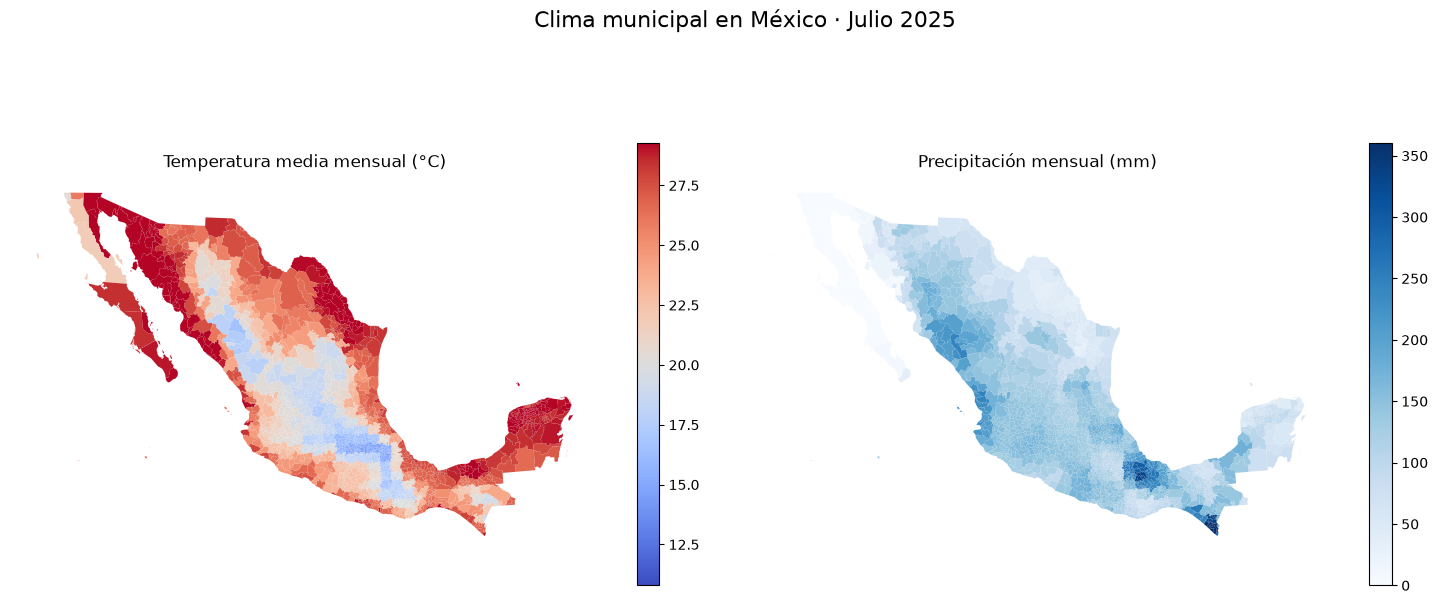

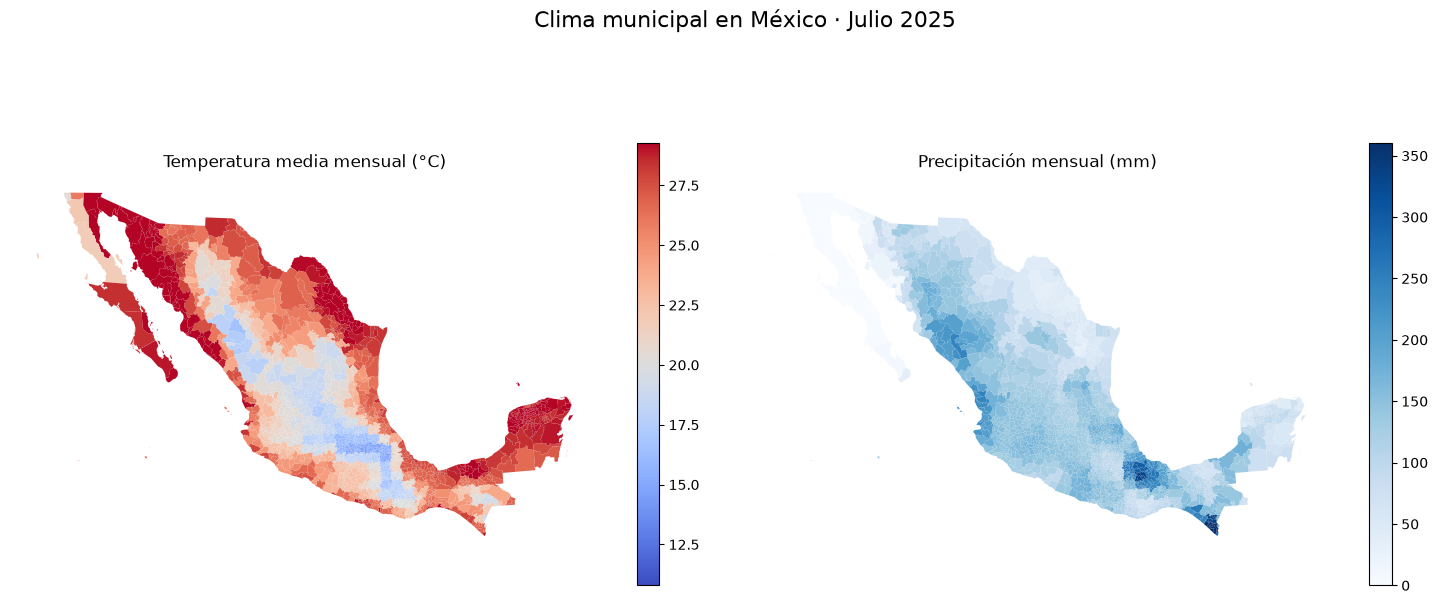

In [14]:
ANIO_CLIMA = 2025
MES_CLIMA = 7

fig, ejes, gdf_mapa_clima = crear_mapa_clima_mensual(
    df_clima_mensual,
    gdf_municipios_mapa,
    anio=ANIO_CLIMA,
    mes=MES_CLIMA,
)
display(fig)

## 8. GIF climático mensual de México

El GIF contiene 276 fotogramas —12 meses por 23 años— y puede tardar varios minutos en generarse. Utiliza geometrías municipales simplificadas para reducir el tiempo y el tamaño del archivo.

In [15]:
GENERAR_GIF_CLIMATICO = False
RUTA_GIF_CLIMATICO = FIGURES_DIR / "clima_mensual_mexico_2003_2025.gif"

if GENERAR_GIF_CLIMATICO:
    ruta_gif = crear_animacion_clima_mensual(
        df_clima_mensual,
        gdf_municipios_mapa,
        ruta_salida=RUTA_GIF_CLIMATICO,
        anio_inicial=2003,
        anio_final=2025,
        fps=6,
        dpi=90,
    )
    print(f"GIF guardado en: {ruta_gif}")
else:
    print("Cambia GENERAR_GIF_CLIMATICO a True para generar el GIF.")

Cambia GENERAR_GIF_CLIMATICO a True para generar el GIF.


## 9. Estado de los conjuntos cargados

En este punto existen tres objetos independientes:

- `df_agricultura_clima`: producción agrícola y clima por municipio-año.
- `gdf_edafologia_area`: polígonos de unidades de suelo.
- `gdf_edafologia_puntos`: perfiles y horizontes de suelo.
- `df_clima_mensual`: temperatura y precipitación mensual por municipio.

La integración espacial se realizará posteriormente, después de definir las características municipales y sus reglas de agregación.

## 10. Preparación del conjunto analítico

Primero se consolida una observación por municipio, año, cultivo, ciclo, modalidad y unidad; el rendimiento se recalcula como producción entre superficie cosechada y se excluyen valores nulos. Para comparar cultivos sin mezclar escalas se construye un rendimiento relativo respecto a la mediana del mismo cultivo, ciclo y unidad. Las anomalías climáticas se calculan contra la historia de cada municipio y ciclo. Se requieren al menos cinco observaciones para estimar una anomalía de rendimiento municipal.

In [16]:
import matplotlib.pyplot as plt
import numpy as np

from proyecto_agronomia.plots import (
    crear_dispersion_con_tendencia,
    crear_heatmap_participacion,
)

columnas_mensuales_actuales = [
    f"{variable}_{mes}_{unidad}"
    for variable, unidad in [("temperatura", "c"), ("precipitacion", "mm")]
    for mes in ["ene", "feb", "mar", "abr", "may", "jun",
                "jul", "ago", "sep", "oct", "nov", "dic"]
]
columnas_mensuales_anteriores = [
    f"{variable}_{mes}_anterior_{unidad}"
    for variable, unidad in [("temperatura", "c"), ("precipitacion", "mm")]
    for mes in ["oct", "nov", "dic"]
]
columnas_mensuales = columnas_mensuales_actuales + columnas_mensuales_anteriores
columnas_analisis = [
    "cvegeo", "Anio", "Nomestado", "Nommunicipio",
    "Nomcultivo", "Nomcicloproductivo", "Nommodalidad", "Nomunidad",
    "Sembrada", "Cosechada", "Siniestrada", "Volumenproduccion",
    "Rendimiento", "precipitacion_ciclo_mm", "temperatura_media_ciclo_c",
    "grupo_suelo_dominante", "nombre_suelo_wrb",
    "grupo_suelo_dominante_pct", "grupos_suelo_n", "textura_dominante",
] + [c for c in columnas_mensuales if c in df_agricultura_clima.columns]
df_analisis = df_agricultura_clima[columnas_analisis].copy()

columnas_numericas = [
    "Sembrada", "Cosechada", "Siniestrada", "Volumenproduccion",
    "Rendimiento", "precipitacion_ciclo_mm", "temperatura_media_ciclo_c",
    "grupo_suelo_dominante_pct", "grupos_suelo_n",
] + [c for c in columnas_mensuales if c in df_analisis.columns]
df_analisis[columnas_numericas] = df_analisis[columnas_numericas].apply(
    pd.to_numeric, errors="coerce"
)
columnas_dimension = [
    "cvegeo", "Anio", "Nomestado", "Nommunicipio", "Nomcultivo",
    "Nomcicloproductivo", "Nommodalidad", "Nomunidad",
    "grupo_suelo_dominante", "nombre_suelo_wrb",
    "grupo_suelo_dominante_pct", "grupos_suelo_n", "textura_dominante",
]
agregaciones = {
    "Sembrada": "sum", "Cosechada": "sum", "Siniestrada": "sum",
    "Volumenproduccion": "sum",
    "precipitacion_ciclo_mm": "first",
    "temperatura_media_ciclo_c": "first",
}
agregaciones.update({columna: "first" for columna in columnas_mensuales if columna in df_analisis})
df_analisis = (
    df_analisis.groupby(columnas_dimension, as_index=False, observed=True, dropna=False)
    .agg(agregaciones)
)
df_analisis["Rendimiento"] = (
    df_analisis["Volumenproduccion"] / df_analisis["Cosechada"]
)
df_analisis = df_analisis.loc[
    df_analisis["Cosechada"].gt(0) & df_analisis["Rendimiento"].gt(0)
].copy()

grupo_comparable = ["Nomcultivo", "Nomcicloproductivo", "Nomunidad"]
mediana_cultivo = df_analisis.groupby(grupo_comparable, observed=True)["Rendimiento"].transform("median")
df_analisis["rendimiento_relativo"] = df_analisis["Rendimiento"] / mediana_cultivo
df_analisis["rendimiento_relativo"] = df_analisis["rendimiento_relativo"].replace([np.inf, -np.inf], np.nan)

claves_clima = ["cvegeo", "Anio", "Nomcicloproductivo"]
df_clima_ciclo = df_analisis[
    claves_clima + ["temperatura_media_ciclo_c", "precipitacion_ciclo_mm"]
].drop_duplicates(claves_clima)
for variable, salida in [
    ("temperatura_media_ciclo_c", "anomalia_temperatura_z"),
    ("precipitacion_ciclo_mm", "anomalia_precipitacion_z"),
]:
    grupo = df_clima_ciclo.groupby(["cvegeo", "Nomcicloproductivo"], observed=True)[variable]
    media = grupo.transform("mean")
    desviacion = grupo.transform("std")
    df_clima_ciclo[salida] = (df_clima_ciclo[variable] - media) / desviacion.replace(0, np.nan)
df_analisis = df_analisis.merge(
    df_clima_ciclo[claves_clima + ["anomalia_temperatura_z", "anomalia_precipitacion_z"]],
    on=claves_clima, how="left", validate="many_to_one"
)

def zscore_con_minimo(serie, minimo=5):
    validos = serie.dropna()
    desviacion = validos.std()
    if len(validos) < minimo or pd.isna(desviacion) or desviacion == 0:
        return pd.Series(np.nan, index=serie.index)
    return (serie - validos.mean()) / desviacion

grupo_historia = ["cvegeo", "Nomcultivo", "Nomcicloproductivo", "Nommodalidad", "Nomunidad"]
df_analisis["anomalia_rendimiento_z"] = (
    df_analisis.groupby(grupo_historia, observed=True, group_keys=False)["Rendimiento"]
    .transform(zscore_con_minimo)
)

display(pd.DataFrame({
    "registros": [len(df_analisis)],
    "municipios": [df_analisis["cvegeo"].nunique()],
    "cultivos": [df_analisis["Nomcultivo"].nunique()],
    "rendimiento_relativo_pct": [df_analisis["rendimiento_relativo"].notna().mean() * 100],
    "anomalia_rendimiento_pct": [df_analisis["anomalia_rendimiento_z"].notna().mean() * 100],
}).round(2))

,registros,municipios,cultivos,rendimiento_relativo_pct,anomalia_rendimiento_pct
0,634827,2452,439,90.81,84.9


## 11. Cultivos predominantes y desempeño por suelo

La primera figura muestra qué porcentaje de la superficie cosechada de cada grupo de suelo corresponde a los principales cultivos. La tabla posterior compara el rendimiento relativo mediano; valores mayores que 1 indican un rendimiento superior a la mediana nacional del mismo cultivo, ciclo y unidad.

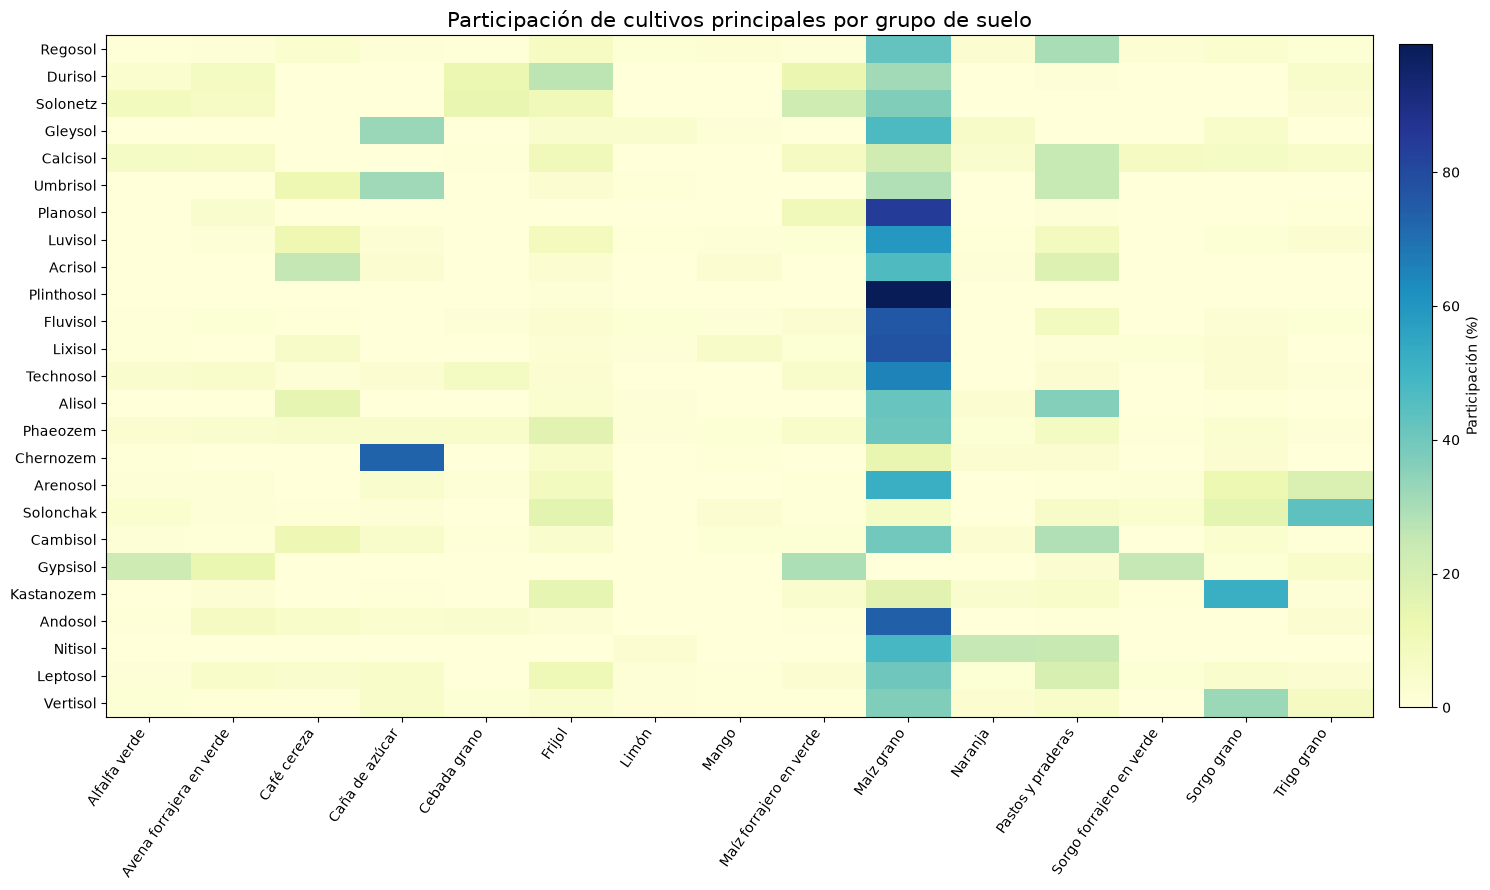

,Nomcultivo,nombre_suelo_wrb,rendimiento_relativo_mediano,registros,superficie_cosechada_ha
7,Alfalfa verde,Durisol,1.164838,427,174261.21
1,Alfalfa verde,Alisol,1.096318,153,3590.05
18,Alfalfa verde,Solonetz,1.094956,48,28190.20
31,Avena forrajera en verde,Gypsisol,1.368692,37,38691.66
26,Avena forrajera en verde,Calcisol,1.158600,1165,389481.29
41,Avena forrajera en verde,Technosol,1.101957,1108,78934.45
46,Café cereza,Andosol,1.510000,568,503256.16
57,Café cereza,Technosol,1.333333,43,26739.42
50,Café cereza,Gleysol,1.266667,34,3994.10
68,Caña de azúcar,Kastanozem,1.445187,34,23325.43


In [17]:
TOP_CULTIVOS = 15
cultivos_principales = (
    df_analisis.groupby("Nomcultivo", observed=True)["Cosechada"].sum()
    .nlargest(TOP_CULTIVOS).index
)
superficie_suelo_cultivo = (
    df_analisis.loc[df_analisis["Nomcultivo"].isin(cultivos_principales)]
    .groupby(["nombre_suelo_wrb", "Nomcultivo"], observed=True)["Cosechada"].sum()
    .unstack(fill_value=0)
)
participacion_suelo_cultivo = (
    superficie_suelo_cultivo.div(superficie_suelo_cultivo.sum(axis=1), axis=0) * 100
).round(2)
participacion_suelo_cultivo = participacion_suelo_cultivo.loc[
    participacion_suelo_cultivo.sum(axis=1).sort_values(ascending=False).index
]
fig, ax = crear_heatmap_participacion(
    participacion_suelo_cultivo,
    "Participación de cultivos principales por grupo de suelo",
)
plt.show()

rendimiento_suelo = (
    df_analisis.loc[df_analisis["Nomcultivo"].isin(cultivos_principales)]
    .groupby(["Nomcultivo", "nombre_suelo_wrb"], observed=True)
    .agg(
        rendimiento_relativo_mediano=("rendimiento_relativo", "median"),
        registros=("Rendimiento", "count"),
        superficie_cosechada_ha=("Cosechada", "sum"),
    ).reset_index()
)
rendimiento_suelo = rendimiento_suelo.loc[rendimiento_suelo["registros"].ge(30)]
mejores_suelos_por_cultivo = (
    rendimiento_suelo.sort_values(
        ["Nomcultivo", "rendimiento_relativo_mediano"], ascending=[True, False]
    ).groupby("Nomcultivo", observed=True).head(3)
)
display(mejores_suelos_por_cultivo)

## 12. Rendimiento frente a anomalías climáticas

La línea roja resume la mediana del rendimiento anómalo por cuantiles climáticos. El selector permite repetir el diagnóstico para cualquier cultivo.

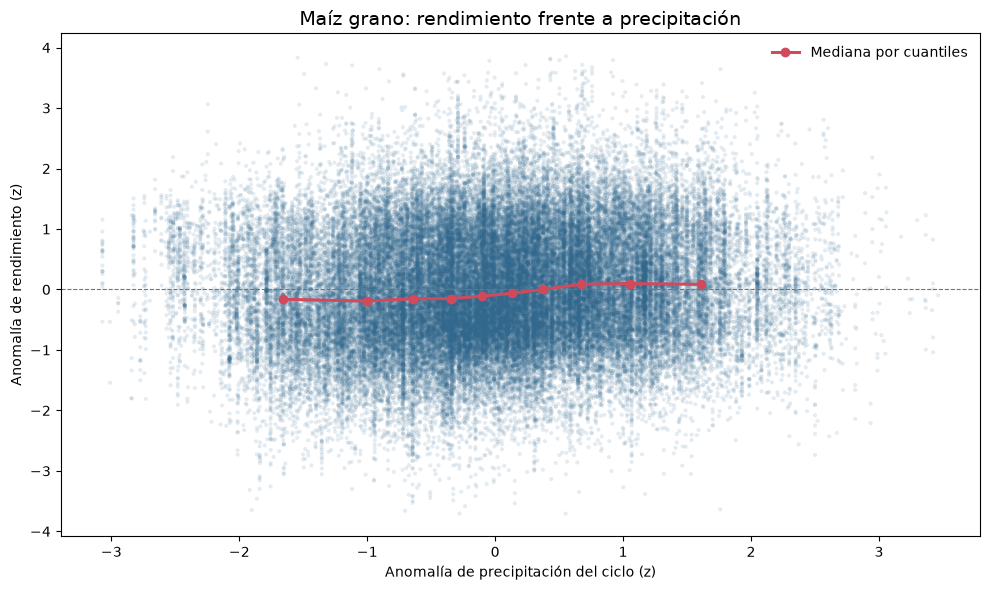

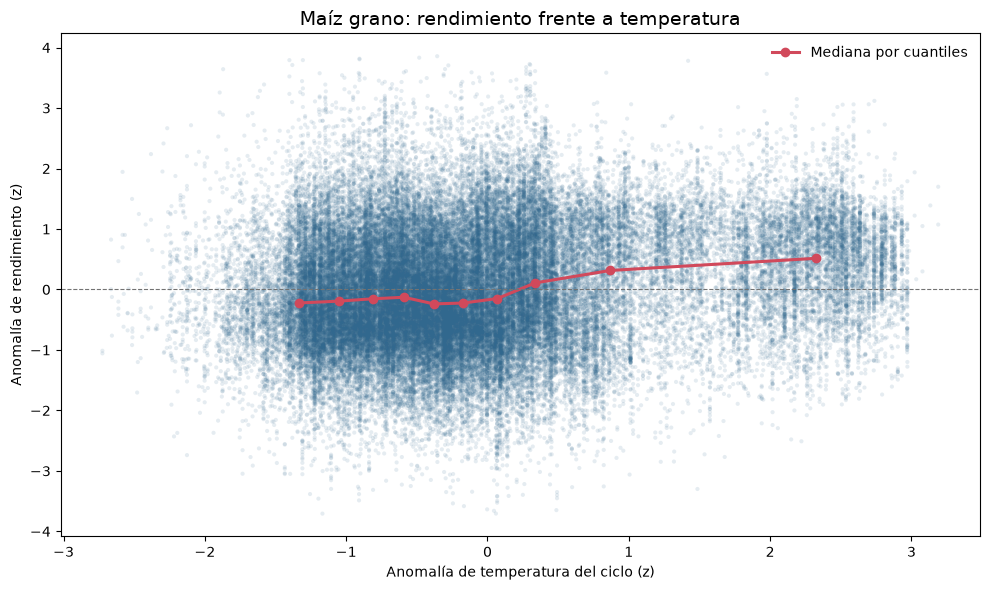

In [18]:
CULTIVO_ANALISIS = cultivos_principales[0]
datos_cultivo = df_analisis.loc[
    df_analisis["Nomcultivo"].eq(CULTIVO_ANALISIS)
]

fig, ax = crear_dispersion_con_tendencia(
    datos_cultivo, x="anomalia_precipitacion_z", y="anomalia_rendimiento_z",
    titulo=f"{CULTIVO_ANALISIS}: rendimiento frente a precipitación",
    etiqueta_x="Anomalía de precipitación del ciclo (z)",
    etiqueta_y="Anomalía de rendimiento (z)",
)
plt.show()

fig, ax = crear_dispersion_con_tendencia(
    datos_cultivo, x="anomalia_temperatura_z", y="anomalia_rendimiento_z",
    titulo=f"{CULTIVO_ANALISIS}: rendimiento frente a temperatura",
    etiqueta_x="Anomalía de temperatura del ciclo (z)",
    etiqueta_y="Anomalía de rendimiento (z)",
)
plt.show()

## 13. Meses sensibles, efecto del suelo y resiliencia

Las correlaciones de Spearman utilizan solamente los meses pertenecientes a cada ciclo: octubre anterior–marzo para Otoño–Invierno, abril–septiembre para Primavera–Verano y enero–diciembre para Perennes. Después se compara cada condición seca, cálida o seca y cálida contra los años normales del mismo cultivo y suelo. Son asociaciones exploratorias y requieren controlar modalidad, región y tendencia temporal en una etapa estadística posterior.

In [19]:
variables_por_ciclo = {
    "Otoño-Invierno": [
        f"{variable}_{mes}_anterior_{unidad}"
        for variable, unidad in [("temperatura", "c"), ("precipitacion", "mm")]
        for mes in ["oct", "nov", "dic"]
    ] + [
        f"{variable}_{mes}_{unidad}"
        for variable, unidad in [("temperatura", "c"), ("precipitacion", "mm")]
        for mes in ["ene", "feb", "mar"]
    ],
    "Primavera-Verano": [
        f"{variable}_{mes}_{unidad}"
        for variable, unidad in [("temperatura", "c"), ("precipitacion", "mm")]
        for mes in ["abr", "may", "jun", "jul", "ago", "sep"]
    ],
    "Perennes": columnas_mensuales_actuales,
}
correlaciones_mensuales = []
for cultivo in cultivos_principales:
    for ciclo, variables_ciclo in variables_por_ciclo.items():
        datos = df_analisis.loc[
            df_analisis["Nomcultivo"].eq(cultivo)
            & df_analisis["Nomcicloproductivo"].eq(ciclo)
        ]
        for variable in [c for c in variables_ciclo if c in datos.columns]:
            pares = datos[[variable, "anomalia_rendimiento_z"]].dropna()
            if len(pares) >= 100:
                correlaciones_mensuales.append({
                    "Nomcultivo": cultivo,
                    "Nomcicloproductivo": ciclo,
                    "variable_climatica": variable,
                    "correlacion_spearman": pares.corr(method="spearman").iloc[0, 1],
                    "registros": len(pares),
                })
df_correlaciones_mensuales = pd.DataFrame(correlaciones_mensuales)
df_correlaciones_mensuales["correlacion_absoluta"] = (
    df_correlaciones_mensuales["correlacion_spearman"].abs()
)
meses_mas_asociados = (
    df_correlaciones_mensuales.sort_values(
        ["Nomcultivo", "Nomcicloproductivo", "correlacion_absoluta"],
        ascending=[True, True, False]
    ).groupby(["Nomcultivo", "Nomcicloproductivo"], observed=True).head(5)
)
display(meses_mas_asociados)

correlaciones_precipitacion_suelo = []
base_precipitacion_suelo = df_analisis.loc[
    df_analisis["Nomcultivo"].isin(cultivos_principales),
    ["Nomcultivo", "nombre_suelo_wrb", "anomalia_precipitacion_z",
     "anomalia_rendimiento_z"],
].dropna()
for (cultivo, suelo), datos in base_precipitacion_suelo.groupby(
    ["Nomcultivo", "nombre_suelo_wrb"], observed=True
):
    if len(datos) >= 100:
        correlaciones_precipitacion_suelo.append({
            "Nomcultivo": cultivo, "nombre_suelo_wrb": suelo,
            "correlacion_precipitacion_rendimiento": datos[
                ["anomalia_precipitacion_z", "anomalia_rendimiento_z"]
            ].corr(method="spearman").iloc[0, 1],
            "registros": len(datos),
        })
df_correlacion_precipitacion_suelo = pd.DataFrame(correlaciones_precipitacion_suelo)
display(df_correlacion_precipitacion_suelo.sort_values(
    "correlacion_precipitacion_rendimiento", ascending=False
).head(30))

es_seco = df_analisis["anomalia_precipitacion_z"].le(-1)
es_calido = df_analisis["anomalia_temperatura_z"].ge(1)
df_analisis["condicion_climatica"] = np.select(
    [es_seco & es_calido, es_seco, es_calido],
    ["Seco y cálido", "Seco", "Cálido"],
    default="Normal",
)
respuesta_suelo = (
    df_analisis.loc[df_analisis["Nomcultivo"].isin(cultivos_principales)]
    .groupby(
        ["Nomcultivo", "nombre_suelo_wrb", "condicion_climatica"],
        observed=True,
    )
    .agg(
        respuesta_mediana_z=("anomalia_rendimiento_z", "median"),
        registros=("anomalia_rendimiento_z", "count"),
    ).reset_index()
)
respuesta_normal = (
    respuesta_suelo.loc[respuesta_suelo["condicion_climatica"].eq("Normal"),
                        ["Nomcultivo", "nombre_suelo_wrb",
                         "respuesta_mediana_z", "registros"]]
    .rename(columns={
        "respuesta_mediana_z": "respuesta_normal_z",
        "registros": "registros_normales",
    })
)
respuesta_adversa_suelo = respuesta_suelo.loc[
    respuesta_suelo["condicion_climatica"].ne("Normal")
].merge(
    respuesta_normal,
    on=["Nomcultivo", "nombre_suelo_wrb"],
    how="inner",
    validate="many_to_one",
)
respuesta_adversa_suelo["diferencia_vs_normal_z"] = (
    respuesta_adversa_suelo["respuesta_mediana_z"]
    - respuesta_adversa_suelo["respuesta_normal_z"]
)
respuesta_adversa_suelo = respuesta_adversa_suelo.loc[
    respuesta_adversa_suelo["registros"].ge(30)
    & respuesta_adversa_suelo["registros_normales"].ge(30)
]
candidatos_resilientes = (
    respuesta_adversa_suelo.sort_values(
        ["Nomcultivo", "condicion_climatica", "diferencia_vs_normal_z"],
        ascending=[True, True, False],
    ).groupby(["Nomcultivo", "condicion_climatica"], observed=True).head(3)
)
display(candidatos_resilientes)

,Nomcultivo,Nomcicloproductivo,variable_climatica,correlacion_spearman,registros,correlacion_absoluta
298,Alfalfa verde,Perennes,temperatura_nov_c,0.125449,11517,0.125449
290,Alfalfa verde,Perennes,temperatura_mar_c,0.115156,11517,0.115156
292,Alfalfa verde,Perennes,temperatura_may_c,0.107524,11517,0.107524
296,Alfalfa verde,Perennes,temperatura_sep_c,0.098325,11517,0.098325
288,Alfalfa verde,Perennes,temperatura_ene_c,0.095083,11517,0.095083
...,...,...,...,...,...,...
191,Trigo grano,Primavera-Verano,precipitacion_sep_mm,0.076750,4790,0.076750
188,Trigo grano,Primavera-Verano,precipitacion_jun_mm,0.067467,4790,0.067467
189,Trigo grano,Primavera-Verano,precipitacion_jul_mm,0.047808,4790,0.047808
190,Trigo grano,Primavera-Verano,precipitacion_ago_mm,0.046240,4790,0.046240


,Nomcultivo,nombre_suelo_wrb,correlacion_precipitacion_rendimiento,registros
116,Maíz grano,Fluvisol,0.352999,487
104,Maíz forrajero en verde,Planosol,0.324524,191
57,Frijol,Alisol,0.285266,1628
184,Trigo grano,Kastanozem,0.281768,127
112,Maíz grano,Arenosol,0.279873,474
157,Sorgo forrajero en verde,Kastanozem,0.277336,102
183,Trigo grano,Durisol,0.261618,252
176,Sorgo grano,Technosol,0.259272,155
154,Sorgo forrajero en verde,Calcisol,0.253405,1102
115,Maíz grano,Durisol,0.228586,984


,Nomcultivo,nombre_suelo_wrb,condicion_climatica,respuesta_mediana_z,registros,respuesta_normal_z,registros_normales,diferencia_vs_normal_z
14,Alfalfa verde,Cambisol,Cálido,1.120291,50,-0.287619,376,1.407910
45,Alfalfa verde,Regosol,Cálido,1.080806,94,-0.232214,637,1.313021
36,Alfalfa verde,Luvisol,Cálido,0.769266,87,-0.241239,557,1.010505
6,Alfalfa verde,Andosol,Seco,0.130134,41,-0.100629,381,0.230763
15,Alfalfa verde,Cambisol,Seco,-0.135723,44,-0.287619,376,0.151896
...,...,...,...,...,...,...,...,...
893,Trigo grano,Vertisol,Seco,0.072605,230,0.020080,1186,0.052525
850,Trigo grano,Calcisol,Seco,-0.227818,71,-0.056435,341,-0.171383
845,Trigo grano,Andosol,Seco y cálido,0.484944,45,-0.152125,492,0.637069
894,Trigo grano,Vertisol,Seco y cálido,0.337066,134,0.020080,1186,0.316986


## 14. Diversidad edafológica, diversidad agrícola y condiciones marginales

La diversidad agrícola se expresa como el número promedio de cultivos por año y se limita a municipios con al menos diez años observados. Los casos marginales combinan clima extremo con una asociación suelo–cultivo que representa menos de 5% de la superficie nacional de ese cultivo; deben interpretarse como candidatos para revisión, no como una clasificación agronómica definitiva.

Correlación Spearman entre diversidad de suelo y cultivos promedio anuales (municipios con 10+ años): 0.453


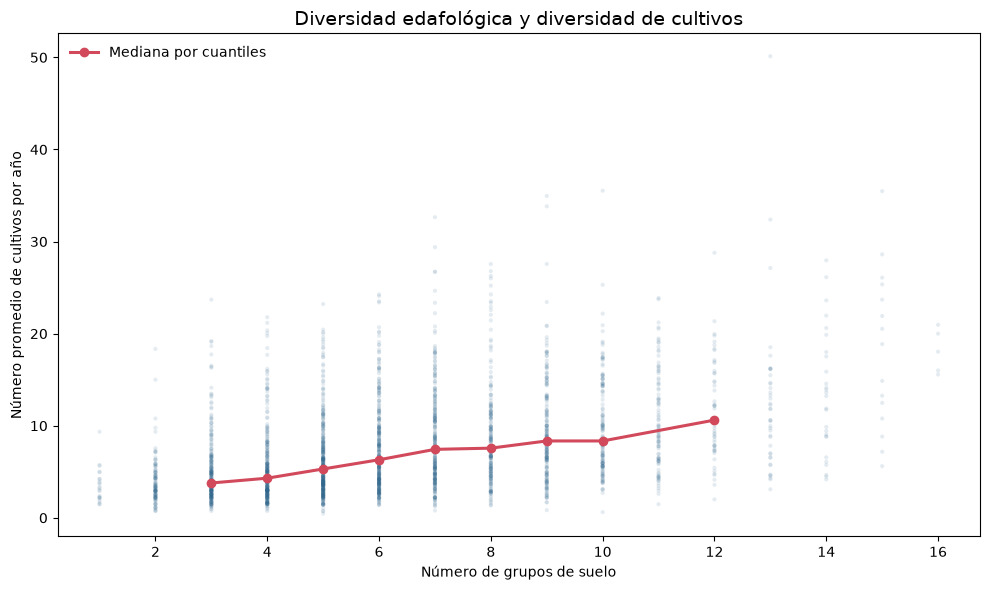

,cvegeo,Nomestado,Nommunicipio,Anio,Nomcultivo,Nomcicloproductivo,nombre_suelo_wrb,participacion_suelo_en_cultivo_pct,anomalia_temperatura_z,anomalia_precipitacion_z,anomalia_rendimiento_z
444648,21140,Puebla,San Pedro Cholula,2005,Pera,Perennes,Technosol,2.110210,0.648470,-2.156658,-3.616374
262318,16064,Michoacán,Parácuaro,2013,Guayaba,Perennes,Vertisol,3.025454,-0.663758,2.023289,-3.526606
587280,30198,Veracruz,Zacualpan,2025,Caña de azúcar piloncillo,Perennes,Luvisol,4.170900,0.940345,2.065611,-3.422628
116031,12021,Guerrero,Coyuca de Benítez,2010,Café cereza,Perennes,Lixisol,0.627012,-2.009552,0.716872,-3.358379
581723,30169,Veracruz,José Azueta,2010,Sandía,Primavera-Verano,Gleysol,3.429142,-0.272920,2.504954,-3.322237
587806,30202,Veracruz,Zontecomatlán de López Y Fuentes,2025,Caña de azúcar piloncillo,Perennes,Umbrisol,1.551917,0.940345,2.065611,-3.318298
583657,30180,Veracruz,Tlachichilco,2025,Caña de azúcar piloncillo,Perennes,Luvisol,4.170900,0.940345,2.065611,-3.235277
412119,21019,Puebla,Atlixco,2010,Cebolla,Otoño-Invierno,Regosol,3.399131,-1.834153,2.149381,-3.102029
443734,21136,Puebla,San Miguel Xoxtla,2005,Pera,Perennes,Phaeozem,3.401046,0.648470,-2.156658,-2.984837
505902,26025,Sonora,Empalme,2005,Melón,Otoño-Invierno,Cambisol,4.328216,-1.665014,2.395416,-2.983920


In [20]:
diversidad_anual = (
    df_analisis.groupby(["cvegeo", "Anio"], observed=True)
    .agg(cultivos_n=("Nomcultivo", "nunique"))
    .reset_index()
)
atributos_municipales = (
    df_analisis.groupby("cvegeo", observed=True)
    .agg(
        grupos_suelo_n=("grupos_suelo_n", "first"),
        municipio=("Nommunicipio", "first"),
        estado=("Nomestado", "first"),
    ).reset_index()
)
diversidad_municipal = (
    diversidad_anual.groupby("cvegeo", observed=True)
    .agg(
        cultivos_promedio_anual=("cultivos_n", "mean"),
        anios_observados=("Anio", "nunique"),
    ).reset_index()
    .merge(atributos_municipales, on="cvegeo", how="left", validate="one_to_one")
)
diversidad_comparable = diversidad_municipal.loc[
    diversidad_municipal["anios_observados"].ge(10)
].dropna(subset=["grupos_suelo_n", "cultivos_promedio_anual"])
correlacion_diversidad = diversidad_comparable[
    ["grupos_suelo_n", "cultivos_promedio_anual"]
].corr(method="spearman").iloc[0, 1]
print(
    "Correlación Spearman entre diversidad de suelo y cultivos promedio anuales "
    f"(municipios con 10+ años): {correlacion_diversidad:.3f}"
)
fig, ax = crear_dispersion_con_tendencia(
    diversidad_comparable, x="grupos_suelo_n", y="cultivos_promedio_anual",
    titulo="Diversidad edafológica y diversidad de cultivos",
    etiqueta_x="Número de grupos de suelo",
    etiqueta_y="Número promedio de cultivos por año",
)
plt.show()

presencia_suelo_cultivo = (
    df_analisis.groupby(["Nomcultivo", "nombre_suelo_wrb"], observed=True)
    .agg(
        superficie_suelo_cultivo=("Cosechada", "sum"),
        registros_suelo_cultivo=("Cosechada", "size"),
    ).reset_index()
)
presencia_suelo_cultivo["participacion_suelo_en_cultivo_pct"] = (
    presencia_suelo_cultivo["superficie_suelo_cultivo"]
    / presencia_suelo_cultivo.groupby("Nomcultivo", observed=True)[
        "superficie_suelo_cultivo"
    ].transform("sum") * 100
)
base_marginalidad = df_analisis.merge(
    presencia_suelo_cultivo,
    on=["Nomcultivo", "nombre_suelo_wrb"],
    how="left",
    validate="many_to_one",
)
casos_marginales = base_marginalidad.loc[
    (base_marginalidad["anomalia_temperatura_z"].abs().ge(2)
     | base_marginalidad["anomalia_precipitacion_z"].abs().ge(2))
    & base_marginalidad["participacion_suelo_en_cultivo_pct"].lt(5)
    & base_marginalidad["registros_suelo_cultivo"].ge(10),
    ["cvegeo", "Nomestado", "Nommunicipio", "Anio", "Nomcultivo",
     "Nomcicloproductivo", "nombre_suelo_wrb",
     "participacion_suelo_en_cultivo_pct", "anomalia_temperatura_z",
     "anomalia_precipitacion_z", "anomalia_rendimiento_z"],
].sort_values("anomalia_rendimiento_z")
display(casos_marginales.head(30))